## Synthetic Dataset Creation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

np.random.seed(42)

#genrating a synthetic dataset with 2 classes
X, y = make_blobs(n_samples=250, centers=2, n_features=2, cluster_std=1.4, random_state=42)
#reshaping to be a column vector for consistency with model's input shape
y = y.reshape(-1, 1)

print(f"Features shape (X): {X.shape}")  # (250, 2)
print(f"Labels shape (y):   {y.shape}")  # (250, 1)

Features shape (X): (250, 2)
Labels shape (y):   (250, 1)


## 2. Logistic Regression Implementation

### Key Components

* **Numerical Stability (Clipping):**
  * **Sigmoid Activation:** $\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$. To prevent floating-point overflow (`NaN` or `inf`) when computing $e^{-z}$ for extreme values of $z$, we clip $z$ to $[-250, 250]$.
  * **Loss Stability:** In Binary Cross-Entropy, $\log(0)$ produces $-\infty$. Predicted probabilities are clipped to $[\epsilon, 1 - \epsilon]$ (where $\epsilon = 10^{-15}$) before computing log loss:
    $$J(w, b) = -\frac{1}{N} \sum_{i=1}^{N} \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right]$$

* **Vectorized Gradient Descent (`fit`):**
  * Predictions: $\hat{y} = \sigma(Xw + b)$
  * Residual error: $\text{error} = \hat{y} - y$
  * Weight gradient: $\frac{\partial J}{\partial w} = \frac{1}{N} X^T (\hat{y} - y)$
  * Bias gradient: $\frac{\partial J}{\partial b} = \frac{1}{N} \sum (\hat{y} - y)$
  * Parameter updates per iteration:
    $$w := w - \alpha \frac{\partial J}{\partial w}, \quad b := b - \alpha \frac{\partial J}{\partial b}$$

* **Inference (`predict` & `predict_proba`):**
  * `predict_proba(X)` computes raw class probabilities $P(Y=1 \mid X)$.
  * `predict(X, threshold=0.5)` applies a hard decision threshold, mapping probabilities $\ge 0.5$ to class `1` and values $< 0.5$ to class `0`.

In [2]:
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def sigmoid(self, z): 
        #clipping to avoid floating point overflow for large values of z (+ve or -ve)
        z_clipped = np.clip(z, -250, 250)
        return 1.0 / (1.0 + np.exp(-z_clipped))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.weights = np.zeros((n_features, 1))
        self.bias = 0.0
        self.loss_history = []

        for i in range(self.n_iterations):
            z = np.dot(X, self.weights) + self.bias
            y_hat = self.sigmoid(z)

            #binary cross entropy loss with clipping to avoid log(0) issues
            eps = 1e-15
            y_hat_safe = np.clip(y_hat, eps, 1 - eps)
            loss = -np.mean(y * np.log(y_hat_safe) + (1 - y) * np.log(1 - y_hat_safe))
            self.loss_history.append(loss)

            #vectorized gradients
            # dw = (1/N) * X^T (y_hat - y), db = (1/N) * sum(y_hat - y)
            error = y_hat - y
            dw = (1.0 / n_samples) * np.dot(X.T, error)
            db = (1.0 / n_samples) * np.sum(error)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self.sigmoid(z)

    def predict(self, X, threshold=0.5):
        probs = self.predict_proba(X)
        return (probs >= threshold).astype(int)

In [3]:
# Instantiate and fit
model = LogisticRegression(learning_rate=0.2, n_iterations=800)
model.fit(X, y)

# Predict on training set
predictions = model.predict(X)
accuracy = np.mean(predictions == y) * 100

print(f"Final Loss: {model.loss_history[-1]:.4f}")
print(f"Trained Weights: w1 = {model.weights[0, 0]:.4f}, w2 = {model.weights[1, 0]:.4f}")
print(f"Trained Bias:    b  = {model.bias:.4f}")
print(f"Training Accuracy: {accuracy:.2f}%")

Final Loss: 0.0038
Trained Weights: w1 = 2.1928, w2 = -0.6505
Trained Bias:    b  = 0.6111
Training Accuracy: 100.00%


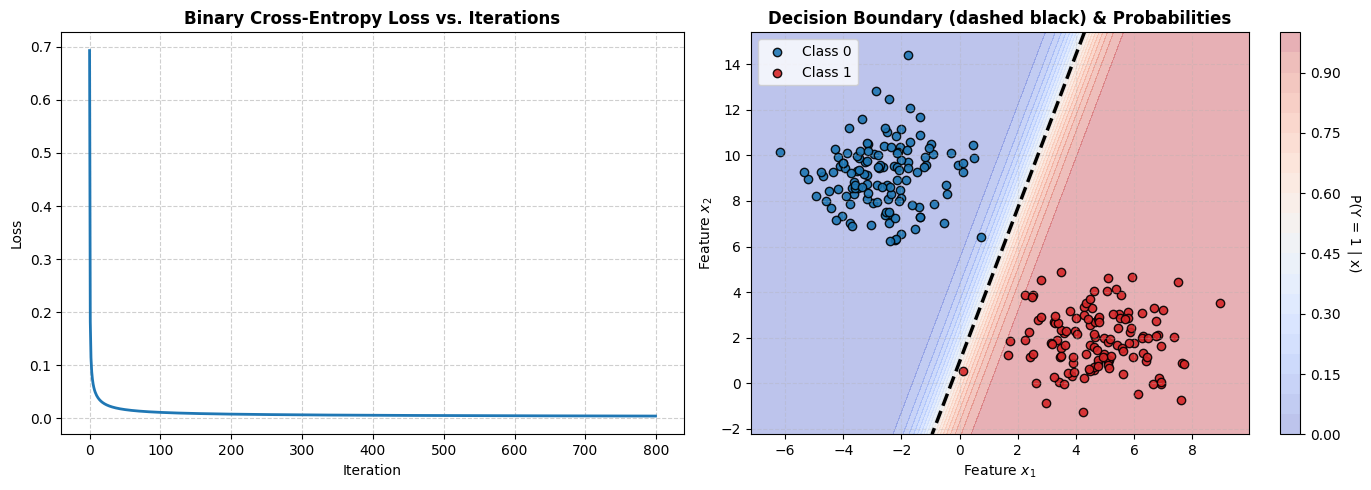

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#loss curve
axes[0].plot(model.loss_history, color="#1f77b4", lw=2)
axes[0].set_title("Binary Cross-Entropy Loss vs. Iterations", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Loss")
axes[0].grid(True, linestyle="--", alpha=0.6)

#decision boundary and probability contours
x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))

grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = model.predict_proba(grid_points).reshape(xx.shape)

#filled contours
contour = axes[1].contourf(xx, yy, probs, levels=20, cmap="coolwarm", alpha=0.35)
cbar = plt.colorbar(contour, ax=axes[1])
cbar.set_label("P(Y = 1 | x)", rotation=270, labelpad=15)

axes[1].contour(xx, yy, probs, levels=[0.5], colors="black", linewidths=2.5, linestyles="--")

#scatterplot
y_flat = y.ravel()
axes[1].scatter(X[y_flat == 0, 0], X[y_flat == 0, 1], color="#1f77b4", edgecolor="k", label="Class 0", alpha=0.9)
axes[1].scatter(X[y_flat == 1, 0], X[y_flat == 1, 1], color="#d62728", edgecolor="k", label="Class 1", alpha=0.9)

axes[1].set_title("Decision Boundary (dashed black) & Probabilities", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Feature $x_1$")
axes[1].set_ylabel("Feature $x_2$")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()